- 假设您需要构建一个处理客户支持邮件的 AI 代理。您的产品团队提出了以下要求：
    - 代理应能够：
        - 阅读收到的客户邮件
        - 按紧急程度和主题进行分类
        - 搜索相关文档以回答问题
        - 起草适当的回复
        - 将复杂问题升级给人工客服
        - 在需要时安排后续跟进
    - 需要处理的示例场景：
        1. 简单的产品问题：“如何重置密码？”
        2. 错误报告：“当我选择 PDF 格式时，导出功能会崩溃。”
        3. 紧急的账单问题：“我的订阅被重复扣费了！”
        4. 功能请求：“能否在移动应用中增加深色模式？”
        5. 复杂的技术问题：“我们的 API 集成间歇性失败，出现 504 错误。”

- 要在 LangGraph 中实现一个代理，通常需要遵循以下五个步骤。
    - 步骤 1：将工作流程分解为离散的步骤。
    - 步骤 2：明确每个步骤需要执行的操作。
    - 步骤 3：设计您的状态。
    - 步骤 4：构建您的节点。
    - 步骤 5：将它们连接起来。

```mermaid
flowchart TD
    START --> ReadEmail
    ReadEmail --> ClassifyIntent
    ClassifyIntent -.-> DocSearch
    ClassifyIntent -.-> BugTrack
    ClassifyIntent -.-> HumanReview1
    DocSearch --> DraftReply
    BugTrack --> DraftReply
    HumanReview1 --> DraftReply
    DraftReply -.-> HumanReview2
    DraftReply -.-> SendReply
    HumanReview2 --> END
    SendReply --> END
```

# 流程梳理

核心业务是：读取邮件内容并分析意图 -> (解析意图，执行路由向下执行) -> 意图的结果处理 -> (中断判断) -> 回复 -> END

- 既然我们已经确定了工作流程中的各个组件，接下来让我们明确每个节点需要执行的操作：
    - **读取邮件**：
        - 提取并解析邮件内容。
    - **意图分类**：
        - 使用 LLM 对紧急程度和主题进行分类，然后路由至相应操作。
    - **文档搜索**：
        - 在知识库中查询相关信息。
    - **缺陷追踪**：
        - 在追踪系统中创建或更新问题。
    - **草拟回复**：
        - 生成合适的回复内容。
    - **人工审核**：
        - 升级至人工客服进行审批或处理。
    - **发送回复**：
        - 发送邮件回复。

In [16]:
from __future__ import annotations
from langchain_ollama import ChatOllama
from langgraph.graph import StateGraph, END, START
from typing import Annotated, TypedDict, Literal
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Command, RetryPolicy
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph.message import add_messages
from langchain_core.runnables import RunnableConfig, ConfigurableField

## 状态设计

In [10]:
class EmailAgentState(TypedDict):
    # 原始数据(输入)
    email_content: str
    sender_email: str
    email_id: str
    # 邮件类别state
    classification: EmailClassification | None  # 节点invoke的中间状态
    # 原始搜索(RAG) 可以是web、MIS、数据库
    search_result: list[str] | None
    # 该用户的历史问题
    customer_history: dict | None
    # 处理的结果数据(输出)
    draft_response: str | None
    messages: list[str] | None
    # messages: Annotation[[BaseMessage], add_messages]

class EmailClassification(TypedDict):
    intent: Literal["question", "bug", "billing", "feature", "complex"]
    urgency: Literal["low", "medium", "high", "critical"]
    topic: str
    summary: str

In [4]:
model_name = "qwen2.5:7b-instruct-q4_K_M"

config = RunnableConfig(
    temperature=0.8,
    configurable={
        "thread_id": "01"
    }
)

model = ChatOllama(model=model_name)

## 节点设计

邮件读取节点

In [32]:
def read_email(state: EmailAgentState) -> dict:
    """Extract and parse email content"""
    # 在生产环境中，这将连接到您的邮件服务
    print(f"邮件内容:{state.get("email_content")}")
    return {
        "messages": [HumanMessage(content=f"正在处理邮件: {state['email_content']}")]
    }

意图分类

In [55]:
def classify_intent(state: EmailAgentState) -> Command[Literal["search_documentation", "human_review", "draft_response", "bug_tracking"]] | dict:
    """
    解析意图, 利用LLM对邮件的意图，紧急程度进行分类，根据分类结果路由到下一个节点
    """
    # 结构化输出节点
    structured_llm = model.with_structured_output(EmailClassification)  # 意图分类
    # 设置提示词，通常由专门的模板供引用
    classification_prompt = f"""
    分析此客户邮件，并进行分类:

    邮件内容: {state["email_content"]}
    发件人: {state["sender_email"]}

    请提供分类结果，包括意图、紧急程度、主题与摘要。
    """
    # 得到意图分类结果
    classification = structured_llm.invoke(classification_prompt)
    print(classification)
    # 根据分类路由
    if classification["intent"] == "billing" or classification["urgency"] == "critical":
        # 人工审核
        goto = "human_review"
    elif classification["intent"] in ["question", "feature"]:
        # 知识库检索
        goto = "search_documentation"
    elif classification["intent"] == "bug":
        # 处理节点
        goto = "bug_tracking"
    else:
        goto = "draft_response"
        
    return Command(
        update={
            "classification": classification
        },
        goto=goto
    )

文档搜索

In [45]:
def search_documentation(state: EmailAgentState) -> Command[Literal["draft_response"]]:
    """在知识库中搜索相关信息。"""
    # 根据分类结果构建搜索查询。
    classification = state.get('classification', {})
    query = f"{classification.get('intent', '')} {classification.get('topic', '')}"

    try:
        # 在此处实现您的搜索逻辑
        # 存储原始搜索结果，而非格式化文本
        search_results = [
            "通过“设置”>“安全”>“更改密码”来重置密码",
            "密码长度必须至少为12个字符",
            "需包含大写字母、小写字母、数字和符号",
        ]
    except SearchAPIError as e:
        # 对于可恢复的搜索错误，存储错误信息并继续执行。
        search_results = [f"搜索服务暂时不可用。: {str(e)}"]

    return Command(
        update={"search_results": search_results},  # 存储原始结果或错误信息。
        goto="draft_response"
    )

Bug跟踪

In [46]:
def bug_tracking(state: EmailAgentState) -> Command[Literal["draft_response"]]:
    """创建或更新缺陷追踪工单。"""

    # 在您的缺陷追踪系统中创建工单。
    ticket_id = "BUG-12345"  # 将通过 API 创建。

    return Command(
        update={
            "search_results": [f"缺陷工单 {ticket_id} 已创建。"],
            "current_step": "缺陷已追踪"
        },
        goto="draft_response"
    )

定制草稿

In [56]:
def draft_response(state: EmailAgentState) -> Command[Literal["human_review", "send_reply"]]:
    """利用上下文生成响应，并根据质量进行路由。"""

    classification = state.get('classification')
    print(classification)
    # 按需从原始状态数据中格式化上下文。
    context_sections = []

    if state.get('search_results'):
        # 为提示格式化搜索结果。
        formatted_docs = "\n".join([f"- {doc}" for doc in state['search_results']])
        context_sections.append(f"相关文档:\n{formatted_docs}")

    if state.get('customer_history'):
        # 为提示格式化客户数据。
        context_sections.append(f"客户等级: {state['customer_history'].get('tier', 'standard')}")

    # 使用格式化后的上下文构建提示。
    draft_prompt = f"""
    请草拟一封回复此客户邮件的信函：
    {state['email_content']}

    Email intent: {classification.get('intent', 'unknown')}
    Urgency level: {classification.get('urgency', 'medium')}

    {chr(10).join(context_sections)}   # char是换行（Line Feed:LF）

    指南：
    - 保持专业且乐于助人
    - 解决他们的具体问题
    - 在相关时使用提供的文档
    """

    response = model.invoke(draft_prompt)

    # 根据紧急程度和意图判断是否需要人工审核。
    needs_review = (
        classification.get('urgency') in ['high', 'critical'] or
        classification.get('intent') == 'complex'
    )

    # 路由至合适的下一个节点。
    goto = "human_review" if needs_review else "send_reply"

    return Command(
        update={"draft_response": response.content},  # 仅存储原始响应。
        goto=goto
    )

人工审核

In [64]:
from langgraph.types import interrupt
def human_review(state: EmailAgentState) -> Command[Literal["send_reply", END]]:
    
    # 审核者审批的信息细节也需要设计
    """
    {
        "approved": True/False,
        "edited_response": "内容的修改",
        "advise": "意见与需求"
    }
    """
    human_decision = interrupt({  # 这里是程序的设计要点
        "email_id": state.get("email_id"),
        "original_email": state.get("email_content"),
        "draft_response": state.get("draft_response"),
        "urgency": state['classification'].get("urgency"),
        "intent": state['classification'].get("intent"),
        "action": "请审核批准/编辑回复内容",
    }) # 挂起

    if human_decision.get("approved", False):
        return Command(
            update={
                "draft_response": human_decision.get("edited_response", state.get("draft_response"))
            },
            goto="send_reply"
        )
    else:
        return Command(
            update={},
            goto=EDN
        )

邮件发送

In [65]:
def send_reply(state: EmailAgentState) -> dict:
    """发送邮件回复。"""
    # 与邮件服务集成。
    print(f"正在发送回复。: {state['draft_response'][:100]}...")
    return {}

## 构建编译图

In [66]:
workflow = StateGraph(EmailAgentState)

In [67]:
workflow.add_node("read_email", read_email)
workflow.add_node("classify_intent", classify_intent, retry_policy=RetryPolicy(max_attempts=3))
workflow.add_node("search_documentation", search_documentation, retry_policy=RetryPolicy(max_attempts=3))
workflow.add_node("bug_tracking", bug_tracking)
workflow.add_node("draft_response", draft_response)
workflow.add_node("human_review", human_review)
workflow.add_node("send_reply", send_reply)

In [68]:
workflow.set_entry_point("read_email")
workflow.add_edge("read_email", "classify_intent") # 由llm自动路由，不加条件边
workflow.add_edge("send_reply", END)

In [69]:
agent = workflow.compile(checkpointer=MemorySaver())

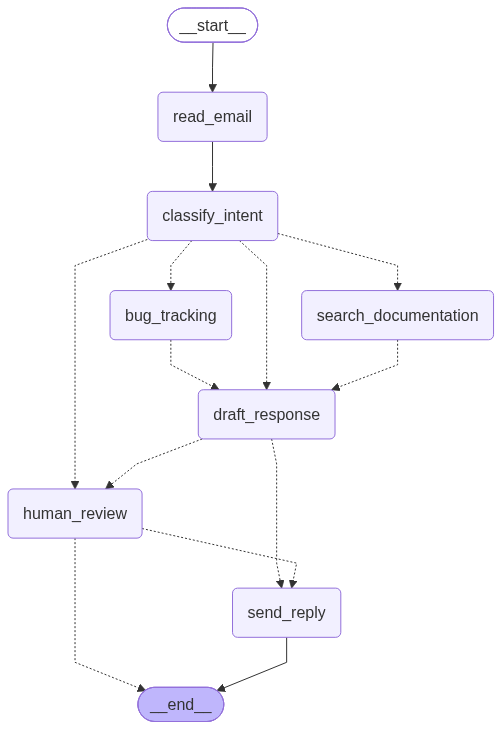

In [21]:
agent

## 测

In [70]:
config = RunnableConfig(
    temperature=0.8,
    configurable={
        "thread_id": "01"
    }
)
initial_state = {
    "email_content": "我的订阅重复扣费了！情况紧急",
    "sender_email": "675817401@qq.com",
    "email_id": "email_1",
    "messages": []
}
result = agent.invoke(
    initial_state,
    config=config
)
print(f"请处理{result['__interrupt__']}")

邮件内容:我的订阅重复扣费了！情况紧急
{'intent': 'complex', 'urgency': 'high', 'topic': '重复扣费问题', 'summary': '客户反映订阅服务出现了重复扣费的情况，要求尽快处理。'}
{'intent': 'complex', 'urgency': 'high', 'topic': '重复扣费问题', 'summary': '客户反映订阅服务出现了重复扣费的情况，要求尽快处理。'}
请处理[Interrupt(value={'email_id': 'email_1', 'original_email': '我的订阅重复扣费了！情况紧急', 'draft_response': '主题：紧急：关于您的订阅重复扣费问题\n\n尊敬的客户，\n\n感谢您联系我们。我们非常抱歉给您带来的不便和焦虑，关于您反馈的订阅重复扣费问题，我们高度重视并立即进行核实。\n\n请您提供一下订阅账号的相关信息，包括但不限于订阅日期、支付方式和最近的交易记录，这将帮助我们更快地定位问题所在。此外，如果您能提供订单号或支付确认邮件的截图，这将对问题的解决大有裨益。\n\n我们承诺在最短的时间内完成调查，并将尽快与您联系，告知具体处理结果。在此之前，如果您有任何疑问或需要进一步的帮助，请随时通过此邮件与我们联系。\n\n为确保此类问题不再发生，我们建议您定期检查账单和订阅状态，如有任何异常情况，请及时与我们联系。我们非常珍视您的信任与支持，将持续努力提供更优质的服务。\n\n如果您遇到其他问题或有任何建议，也请告诉我们。我们将竭尽全力帮助您。\n\n感谢您的理解和合作。祝您生活愉快！\n\n此致\n\n敬礼\n\n阿里巴巴云客户服务团队\n\n[注：请将上述内容中的方括号替换为实际的联系信息或服务热线，具体根据实际情况调整。]\n\n---\n\n以上回复模板按照您的要求保持了专业的态度，同时表达了对客户问题的重视，并提供了具体的解决方案和建议。希望这对您有所帮助。', 'urgency': 'high', 'intent': 'complex', 'action': '请审核批准/编辑回复内容'}, id='732808155ea4412572dfcc5ea182902e')]


In [71]:
human_response = Command(
    resume={
        "approved": True,
        "edited_response": "对于重复扣费，我们深表歉意。我已立即启动了退款流程……"
    }
)

# 恢复执行
final_result = agent.invoke(human_response, config)
print(f"邮件已成功发送！")

正在发送回复。: 对于重复扣费，我们深表歉意。我已立即启动了退款流程……...
邮件已成功发送！
